# Компьютерное зрение — Лабораторная работа 5
## Сегментация фрагментов горной породы (Rock Fragmentation) с YOLOv8-seg

**Задача:** по фотографиям взрывных масс, конвейерных лент и открытых карьеров
сегментировать отдельные фрагменты горной породы (камни). Объекты одного класса —
`stone`.

**Метрика:** средний Dice coefficient между предсказанной бинарной маской и
истинной маской.

**План работы:**

```
┌─────────────┐    ┌──────────────┐    ┌───────────┐    ┌──────────────┐
│ Изучение    │ →  │ Конвертация  │ →  │ Обучение  │ →  │ Инференс и   │
│ данных      │    │ COCO → YOLO  │    │ YOLOv8-seg│    │ оценка Dice  │
│ (COCO JSON) │    │ (dataset/)   │    │           │    │ + submission │
└─────────────┘    └──────────────┘    └───────────┘    └──────────────┘
```

---


## 0. Подготовка окружения

Убедитесь, что установлены нужные библиотеки:

```bash
pip install ultralytics pycocotools pandas matplotlib opencv-python tqdm notebook
```


In [64]:
# !unzip cv5_dataset.zip;

## Импорты и конфигурация путей

In [65]:
import json
import shutil
import csv
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

from tqdm import tqdm
from ultralytics import YOLO

# Пути к файлам проекта
BASE_DIR = Path.cwd()                       # корень проекта (папка с ноутбуком)
TRAIN_JSON = BASE_DIR / "train.json"   # COCO-аннотации train

TRAIN_IMG  = BASE_DIR /  "train"                   # изображения train
VAL_IMG    = BASE_DIR / "test_score"                    # изображения val/test
DATASET_DIR = BASE_DIR / "dataset"                           # датасет для YOLO
OUTPUT_DIR  = BASE_DIR / "predictions"                       # результаты inference

print("Пути готовы", TRAIN_JSON)

Пути готовы D:\python_programming\for_git_repositories\work_folder\STUDY\5._CV5._Фрагментация_пород\train.json


## 1. Изучение датасета

### 1.1. Формат COCO

Аннотации лежат в формате **COCO** (Common Objects in Context):
- `images` — метаданные об изображениях (id, ширина, высота, имя файла);
- `annotations` — аннотации объектов: полигоны, bounding box, площадь, класс;
- `categories` — список классов.

Все изображения уже пережаты до ширины **1024 px**.

In [66]:
# --- Статистика COCO-аннотаций ---

def load_coco(json_path: Path) -> dict:
    """Загрузка COCO JSON."""
    with open(json_path) as f:
        return json.load(f)

coco_train = load_coco(TRAIN_JSON)

images = coco_train["images"]
anns   = coco_train["annotations"]
cats   = coco_train["categories"]

print(f"  Категории:   {[(c['id'], c['name']) for c in cats]}")
print(f"  Изображений: {len(images)}")
print(f"  Аннотаций:   {len(anns)}")

# Среднее число объектов на изображении
anns_per_img = {}
for a in anns:
    anns_per_img[a["image_id"]] = anns_per_img.get(a["image_id"], 0) + 1

print(f"  Объектов на изображение: min={min(anns_per_img.values())}, "
      f"max={max(anns_per_img.values())}, "
      f"среднее={np.mean(list(anns_per_img.values())):.1f}")

# Размеры изображений (пример)
print(f"  Пример записи изображения: {images[0]}")

# Пример аннотации (первые 3)
print("  Пример аннотации:")
for a in anns[:3]:
    print("   ", {k: (v if k != "segmentation" else f"полигон: {len(v[0])//2} точек") 
                   for k, v in a.items()})

  Категории:   [(1, 'stone')]
  Изображений: 554
  Аннотаций:   131135
  Объектов на изображение: min=1, max=1283, среднее=236.7
  Пример записи изображения: {'id': 1, 'width': 1024, 'height': 1833, 'file_name': 'rock_blasting_106.jpg', 'license': 0, 'flickr_url': '', 'coco_url': '', 'date_captured': 0}
  Пример аннотации:
    {'id': 1, 'image_id': 545, 'category_id': 1, 'segmentation': 'полигон: 340 точек', 'area': 27684.0, 'bbox': [793.2480573819486, 1116.8459986550101, 133.43215780035862, 121.78211163416275], 'iscrowd': 0, 'attributes': {'occluded': False}}
    {'id': 2, 'image_id': 545, 'category_id': 1, 'segmentation': 'полигон: 28 точек', 'area': 34803.0, 'bbox': [142.61326957561266, 777.2024209818426, 154.85475194261804, 124.84196368527236], 'iscrowd': 0, 'attributes': {'occluded': False}}
    {'id': 3, 'image_id': 545, 'category_id': 1, 'segmentation': 'полигон: 42 точек', 'area': 47850.0, 'bbox': [0.0, 693.9744451916611, 161.587567244471, 158.50033624747815], 'iscrowd': 0, 'at

### 1.2. Визуализация аннотаций COCO

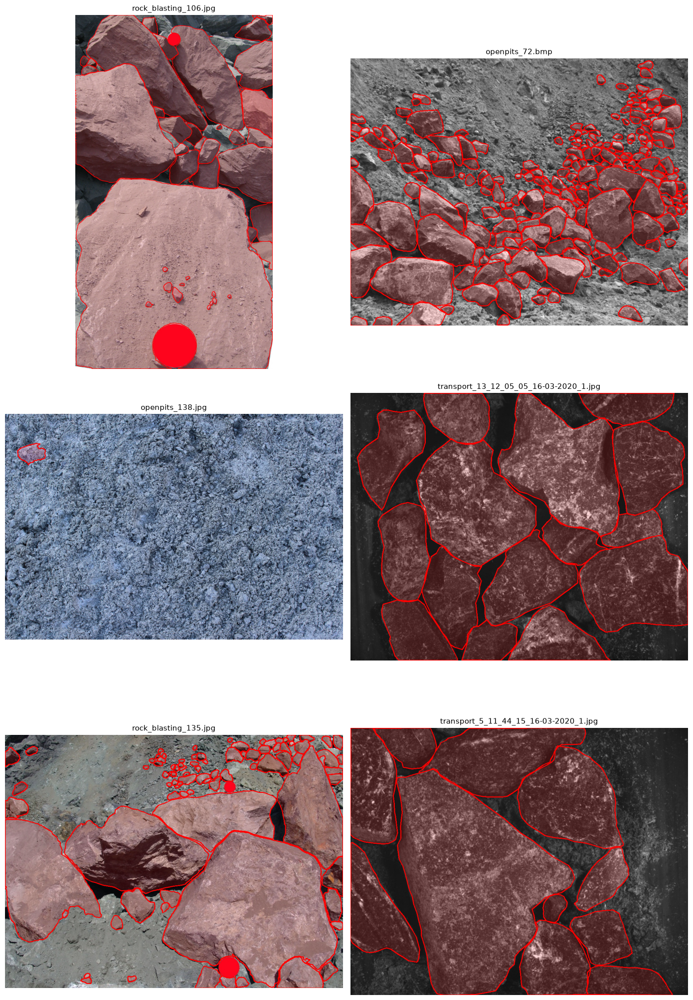

In [67]:
# --- Визуализация COCO-аннотаций (полигоны) ---
def draw_coco_annotations(coco: dict, img_dir: Path, n: int = 4):
    """Рисует изображения с наложенными полигонами из COCO."""
    images = {img["id"]: img for img in coco["images"]}

    # Группируем аннотации по изображению
    anns_by_img = {}
    for a in coco["annotations"]:
        anns_by_img.setdefault(a["image_id"], []).append(a)

    sample_ids = list(images.keys())[:n]
    cols, rows = 2, (n + 1) // 2
    fig, axes = plt.subplots(rows, cols, figsize=(14, 7 * rows))
    axes = np.array(axes).reshape(-1)

    for ax, img_id in zip(axes, sample_ids):
        info = images[img_id]
        img = cv2.imread(str(img_dir / info["file_name"]))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        for ann in anns_by_img.get(img_id, []):
            for polygon in ann["segmentation"]:
                pts = np.array(polygon, dtype=np.int32).reshape(-1, 2)
                cv2.polylines(img, [pts], True, (255, 0, 0), 2)  # контур
                overlay = img.copy()
                cv2.fillPoly(overlay, [pts], (255, 0, 0))
                img = cv2.addWeighted(img, 0.85, overlay, 0.15, 0)  # заливка

        ax.imshow(img)
        ax.set_title(info["file_name"], fontsize=11)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

draw_coco_annotations(coco_train, TRAIN_IMG, n=6)

In [68]:
# --- Краткая справка: структура COCO-аннотации ---

# images:  список записей об изображениях: id, width, height, file_name
# annotations: список объектов:
#     - segmentation: список полигонов ([[x1, y1, x2, y2, ...]])
#     - bbox: [x, y, w, h]
#     - area: площадь объекта
#     - category_id: id класса

# В нашем датасете ВСЕ изображения пережаты до ширины 1024 (это сделано ранее),
# а высота зависит от пропорции. Все объекты относятся к одному классу "stone".

## 2. Подготовка датасета для YOLO

### 2.1. Формат аннотаций YOLOv8-seg

YOLOv8-seg не работает с JSON напрямую — аннотации хранятся в текстовых файлах.
Разберёмся с этим форматом.

In [69]:
# --- Краткая справка: формат YOLO segmentation ---

# YOLOv8-seg ожидает аннотации в текстовых файлах .txt (по одному на изображение),
# содержимое каждой строки:
#
#   <class_id> <x1_норм> <y1_норм> <x2_норм> <y2_норм> ... <xn_норм> <yn_норм>
#
# где координаты НОРМАЛИЗОВАНЫ на [0, 1] и отсортированы по контуру.
#
# Структура датасета:
#   dataset/
#     train/
#       images/  — 554 изображения
#       labels/  — 554 файла .txt
#     val/
#       images/  — 139 изображений
#       labels/  — 139 файлов .txt
#
# Каждый .txt соответствует изображению: images/rock.jpg <-> labels/rock.txt

### 2.2. Конвертация COCO → YOLO

In [70]:
# --- Часть 1: конвертация COCO → YOLO segmentation ---
def convert_coco_to_yolo(coco_json_path: Path, img_src_dir: Path, split: str):
    """Конвертирует один COCO JSON в YOLO-формат для указанного split."""
    with open(coco_json_path) as f:
        coco = json.load(f)

    img_out = DATASET_DIR / split / "images"
    lbl_out = DATASET_DIR / split / "labels"
    img_out.mkdir(parents=True, exist_ok=True)
    lbl_out.mkdir(parents=True, exist_ok=True)

    images = {img["id"]: img for img in coco["images"]}

    # Группируем аннотации по изображениям
    anns_by_img = {}
    for ann in coco["annotations"]:
        anns_by_img.setdefault(ann["image_id"], []).append(ann)

    converted = 0
    for img_id, info in tqdm(images.items(), desc=f"{split}"):
        fname = info["file_name"]
        w, h = info["width"], info["height"]

        src = img_src_dir / fname
        if not src.exists():
            print(f"  [SKIP] {fname} не найден")
            continue

        # 1. Копируем изображение в датасет
        shutil.copy2(src, img_out / fname)

        # 2. Конвертируем каждый полигон в YOLO-строку
        lines = []
        for ann in anns_by_img.get(img_id, []):
            for polygon in ann["segmentation"]:
                if len(polygon) < 6:       # нужно минимум 3 точки
                    continue

                coords = []
                for i in range(0, len(polygon), 2):
                    # Нормализация координат на [0, 1]
                    nx = np.clip(polygon[i] / w, 0.0, 1.0)
                    ny = np.clip(polygon[i + 1] / h, 0.0, 1.0)
                    coords.append(f"{nx:.6f}")
                    coords.append(f"{ny:.6f}")

                # формат: class_id x1 y1 x2 y2 ...
                lines.append("0 " + " ".join(coords))

        # 3. Сохраняем .txt файл (даже пустой, чтобы файл существовал)
        label_path = lbl_out / (Path(fname).stem + ".txt")
        label_path.write_text("\n".join(lines))
        converted += 1

    return converted

# Выполняем конвертацию для train и val
n_train = convert_coco_to_yolo(TRAIN_JSON, TRAIN_IMG, "train")
# n_val   = convert_coco_to_yolo(VAL_JSON,   VAL_IMG,   "val")
print(f"  Конвертировано: train={n_train}")

train: 100%|██████████| 554/554 [02:14<00:00,  4.12it/s]

  Конвертировано: train=554


### 2.3. Проверка конвертации

In [71]:
# --- Проверка результатов конвертации ---

for split in ["train"]:
    img_dir = DATASET_DIR / split / "images"
    lbl_dir = DATASET_DIR / split / "labels"
    imgs = sorted(img_dir.glob("*"))
    lbls = sorted(lbl_dir.glob("*.txt"))
    non_empty = sum(1 for p in lbls if p.stat().st_size > 0)
    print(f"  {split}: {len(imgs)} images, {len(lbls)} labels ({non_empty} непустых)")

# Посмотрим на один конвертированный файл
sample_label = sorted((DATASET_DIR / "train" / "labels").glob("*.txt"))[0]
print(f"\nПример метки: {sample_label}")
with open(sample_label) as f:
    lines = f.read().splitlines()
print("  Количество объектов:", len(lines))
print("  Первая строка:", lines[0] if lines else "  (пусто — нет объектов)")

  train: 554 images, 554 labels (554 непустых)

Пример метки: D:\python_programming\for_git_repositories\work_folder\STUDY\5._CV5._Фрагментация_пород\dataset\train\labels\openpits_101.txt
  Количество объектов: 280
  Первая строка: 0 0.193359 0.615575 0.193359 0.615575 0.192383 0.615575 0.192383 0.615575 0.191406 0.615575 0.191406 0.615575 0.189453 0.615575 0.189453 0.616811 0.180664 0.616811 0.179688 0.616811 0.176758 0.616811 0.176758 0.618047 0.175781 0.618047 0.175781 0.618047 0.173828 0.618047 0.173828 0.619283 0.168945 0.619283 0.167969 0.619283 0.167969 0.619283 0.166992 0.620519 0.166992 0.620519 0.166016 0.620519 0.166016 0.620519 0.164062 0.622991 0.164062 0.624227 0.163086 0.625464 0.163086 0.625464 0.161133 0.626700 0.160156 0.626700 0.158203 0.630408 0.158203 0.630408 0.158203 0.631644 0.158203 0.632880 0.157227 0.634116 0.157227 0.636588 0.158203 0.636588 0.159180 0.636588 0.159180 0.636588 0.159180 0.636588 0.160156 0.637824 0.160156 0.637824 0.160156 0.637824 0.162109 0

### 2.4. Визуализация YOLO-меток

In [72]:
DATASET_DIR

WindowsPath('D:/python_programming/for_git_repositories/work_folder/STUDY/5._CV5._Фрагментация_пород/dataset')

In [73]:
images_files ={x.stem:x for x in (DATASET_DIR / "train" / "images").glob("*")}

D:\python_programming\for_git_repositories\work_folder\STUDY\5._CV5._Фрагментация_пород\dataset\train\labels\openpits_101.txt
D:\python_programming\for_git_repositories\work_folder\STUDY\5._CV5._Фрагментация_пород\dataset\train\labels\openpits_102.txt
D:\python_programming\for_git_repositories\work_folder\STUDY\5._CV5._Фрагментация_пород\dataset\train\labels\openpits_104.txt
D:\python_programming\for_git_repositories\work_folder\STUDY\5._CV5._Фрагментация_пород\dataset\train\labels\openpits_105.txt


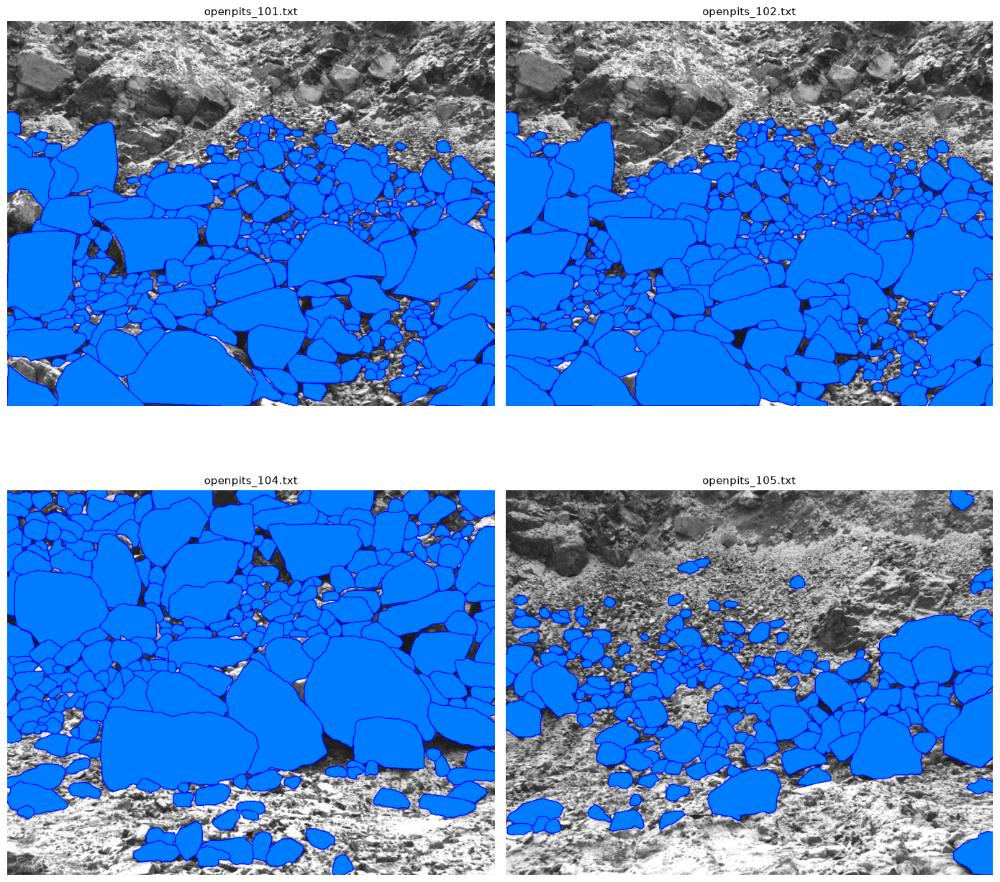

In [74]:
# --- Визуализация: чтение YOLO-меток обратно в изображение ---

def draw_yolo_labels(img_dir: Path, lbl_dir: Path, n: int = 4):
    """Рисует изображения с полигонами из YOLO-меток."""
    lbl_paths = sorted(lbl_dir.glob("*.txt"))[:n]
    images_files ={x.stem:x for x in (img_dir).glob("*")}
    
    cols = 2
    rows = (n + 1) // 2

    
    fig, axes = plt.subplots(rows, cols, figsize=(14, 7 * rows))
    axes = np.array(axes).reshape(-1)
    
    for ax, lbl_path in zip(axes, lbl_paths):
        print(lbl_path)
        img_path = images_files[lbl_path.stem]
        img = cv2.imread(str(img_path))
        h, w = img.shape[:2]
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        with open(lbl_path) as f:
            for line in f.read().splitlines():
                vals = list(map(float, line.split()))
                pts = np.array(vals[1:], dtype=np.float32).reshape(-1, 2)
                pts[:, 0] *= w                     # денормализация x
                pts[:, 1] *= h                     # денормализация y
                pts = pts.astype(np.int32)

                cv2.polylines(img, [pts], True, (0, 0, 255), 3)
                cv2.fillPoly(img, [pts], (0, 125, 255))

        ax.imshow(img)
        ax.set_title(lbl_path.name, fontsize=11)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

draw_yolo_labels(DATASET_DIR / "train" / "images",
                 DATASET_DIR / "train" / "labels", n=4)

### 2.5. Конфигурация датасета (dataset.yaml)

YOLO нужен YAML-файл с путями к данным и списком классов.

In [75]:
# --- Часть 2: конфигурация датасета (dataset.yaml) ---

# YOLO требует YAML-файл с описанием датасета:
#   path  — корневая папка датасета
#   train — относительный путь к train/images
#   val   — относительный путь к val/images
#   names — словарь id → название класса

yaml_content = """# YOLOv8-seg Dataset Config — Rock Fragmentation
path: dataset          # относительный путь от корня проекта
train: train/images    # train изображения
val: train/images        # val изображения

names:
  0: stone             # единственный класс — фрагменты горных пород
nc: 1
"""

dataset_yaml = BASE_DIR / "dataset.yaml"
dataset_yaml.write_text(yaml_content)
print(f"Файл {dataset_yaml} создан")

Файл D:\python_programming\for_git_repositories\work_folder\STUDY\5._CV5._Фрагментация_пород\dataset.yaml создан


## 3. Обучение YOLOv8-seg

In [76]:
# --- Часть 3: обучение YOLOv8-seg ---

# Проверяем, что ultralytics установлена
import ultralytics
print(f"ultralytics версия: {ultralytics.__version__}")

# Файл весов: если его нет локально, ultralytics скачает автоматически.
# Доступные модели (по размеру возрастания):
#   yolov8n-seg.pt  (nano,    самое быстрое)
#   yolov8s-seg.pt  (small,   золотая середина)
#   yolov8m-seg.pt  (medium,  точнее, но медленнее)
#   yolov8l-seg.pt  (large,   тяжёлая)
#   yolov8x-seg.pt  (xlarge,  самая точная/медленная)

MODEL_NAME = "yolov8n-seg.pt"   # начнём с nano для скорости

model = YOLO(MODEL_NAME)        # создаём модель (автозагрузка pretrained-весов)
print("Модель загружена:", MODEL_NAME)

ultralytics версия: 8.4.185
Модель загружена: yolov8n-seg.pt


In [77]:
# --- Запуск обучения ---
# Параметры подобраны для учебного прогона (~несколько минут на GPU).
# Для реального результата можно увеличить epochs и выбрать модель побольше.
# Для реального результата можно увеличить epochs и выбрать модель побольше.

# Задаем базовый путь для сохранения проекта
SAVE_DIR = r"D:\python_programming\for_git_repositories\work_folder\STUDY\5._CV5._Фрагментация_пород\runs"
    
results = model.train(
    data=str(dataset_yaml),     # путь к dataset.yaml
    epochs=5,                  # количество эпох
    batch=4,                    # образов на батч (зависит от VRAM)
    imgsz=480,                  # размер входа
    lr0=0.01,                   # стартовый learning rate
    optimizer="auto",           # выбор оптимизатора
    device='cpu',                   # GPU (0 — первая видеокарта)
    project=SAVE_DIR,
    name="yolo_students",       # имя эксперимента
    workers=4,                  # потоков загрузки данных
    save_period=10,             # контрольная точка каждые 10 эпох
    save=True,                  # сохранять веса
    plots=True,                 # графики обучения
    # --- аугментации (улучшают обобщение) ---
    hsv_h=0.015,                # сдвиг оттенка
    hsv_s=0.7,                  # сдвиг насыщенности
    hsv_v=0.4,                  # сдвиг яркости
    degrees=10.0,               # поворот до 10°
    translate=0.1,              # сдвиг картинки до 10%
    scale=0.3,                  # масштабирование до 30%
    fliplr=0.5,                 # горизонтальный флип (50%)
    mosaic=1.0,                 # мозаика (склейка 4 картинок)
    mixup=0.1,                  # смешивание картинок
    copy_paste=0.1,             # copy-paste объектов
    # --- параметры детекции ---
    conf=0.25,                  # порог уверенности
    iou=0.6,                    # порог IoU для NMS
    max_det=500,                # максимум объектов на изображение
    cache='ram',
    verbose=True,
)

# Результат обучения можно посмотреть в папке runs/segment/yolo_students/:
print("Результаты сохранены в: runs/segment/yolo_students/")

New https://pypi.org/project/ultralytics/8.4.187 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.185  Python-3.12.10 torch-2.14.1+cpu CPU (12th Gen Intel Core i5-12500H)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=0.25, copy_paste=0.1, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\python_programming\for_git_repositories\work_folder\STUDY\5._CV5._Фрагментация_пород\dataset.yaml, degrees=10.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=480, iou=0.6, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, m

### 3.1. Анализ результатов обучения

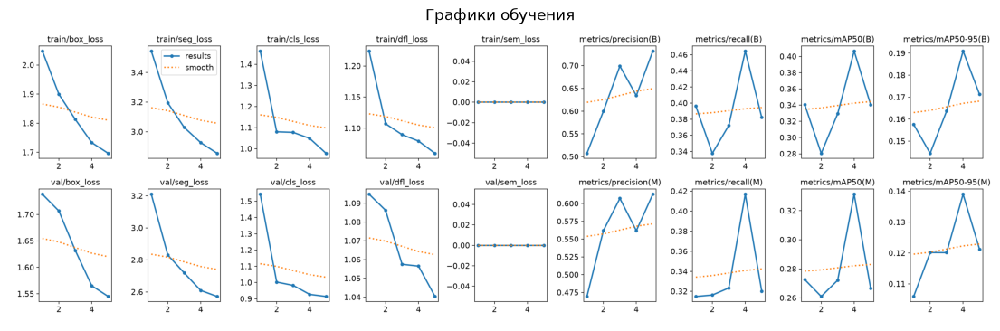

In [78]:
# --- Анализ результатов обучения ---

# В папке эксперимента появились:
#   weights/best.pt  — лучшая модель (по mAP на val)
#   weights/last.pt  — модель с последней эпохи
#   results.png      — графики loss, mAP, precision/recall

# Покажем графики обучения, если файл существует
results_png = BASE_DIR / "runs" / "segment" / "yolo_students" / "results.png"
if results_png.exists():
    img = plt.imread(results_png)
    plt.figure(figsize=(14, 8))
    plt.imshow(img)
    plt.axis("off")
    plt.title("Графики обучения")
    plt.show()
else:
    print("Файл results.png ещё не создан (обучение не завершено)")
    print(results_png)

## 4. Инференс

In [79]:
best_weights

WindowsPath('D:/python_programming/for_git_repositories/work_folder/STUDY/5._CV5._Фрагментация_пород/runs/segment/yolo_students/weights/best.pt')

In [80]:
# --- Часть 4: инференс (предсказание) обученной моделью ---

# Загружаем лучшие веса
best_weights = BASE_DIR / "runs" / "segment"/"yolo_students" / "weights" / "best.pt"
if not best_weights.exists():
    print(f"[!] Нет весов: {best_weights}. Сначала выполните ячейку обучения.")
model = YOLO(str(best_weights))
print("Модель загружена:", best_weights)

Модель загружена: D:\python_programming\for_git_repositories\work_folder\STUDY\5._CV5._Фрагментация_пород\runs\segment\yolo_students\weights\best.pt


In [81]:
VAL_IMG    = BASE_DIR / "test_score"     

In [82]:
# --- Выполнение инференса на тестовых изображениях ---

CONF_THRESH = 0.4  # порог уверенности

# Предсказание по всем изображениям из папки val/test
results = model.predict(
    source=str(VAL_IMG),      # папка с тестовыми изображениями
    imgsz=640,                # размер входа
    conf=CONF_THRESH,         # порог уверенности
    iou=0.6,                  # порог IoU
    max_det=1000,              # максимум объектов
    device='cpu',                 # GPU
    stream=True,              # потоковая обработка
)

# results — генератор: пройдём по нему и соберём маски
results = list(results)

# Собираем предсказанные маски: file_name → единая бинарная маска
pred_masks = {}
for res in results:
    fname = Path(res.path).name
    h, w = res.orig_shape          # исходный размер изображения
    combined = np.zeros((h, w), dtype=np.uint8)

    if res.masks is not None and len(res.masks) > 0:
        for mask_tensor in res.masks.data:
            # Каждая instance-маска (H, W) в масштабе входа модели
            mask = (mask_tensor.cpu().numpy() > CONF_THRESH).astype(np.uint8)
            if mask.shape != (h, w):
                # Возвращаем к исходному размеру изображения
                mask = cv2.resize(mask, (w, h), interpolation=cv2.INTER_NEAREST)
            combined = np.maximum(combined, mask)   # объединение всех объектов

    pred_masks[fname] = combined

print(f"Обработано изображений: {len(pred_masks)}")


image 1/27 D:\python_programming\for_git_repositories\work_folder\STUDY\5._CV5._Фрагментация_пород\test_score\openpits_10.bmp: 512x640 317 stones, 94.6ms
image 2/27 D:\python_programming\for_git_repositories\work_folder\STUDY\5._CV5._Фрагментация_пород\test_score\openpits_208.bmp: 512x640 47 stones, 72.6ms
image 3/27 D:\python_programming\for_git_repositories\work_folder\STUDY\5._CV5._Фрагментация_пород\test_score\openpits_211.bmp: 512x640 357 stones, 93.8ms
image 4/27 D:\python_programming\for_git_repositories\work_folder\STUDY\5._CV5._Фрагментация_пород\test_score\openpits_215.bmp: 512x640 243 stones, 78.2ms
image 5/27 D:\python_programming\for_git_repositories\work_folder\STUDY\5._CV5._Фрагментация_пород\test_score\openpits_40.bmp: 512x640 344 stones, 68.6ms
image 6/27 D:\python_programming\for_git_repositories\work_folder\STUDY\5._CV5._Фрагментация_пород\test_score\openpits_49.bmp: 512x640 296 stones, 69.5ms
image 7/27 D:\python_programming\for_git_repositories\work_folder\STUDY\5

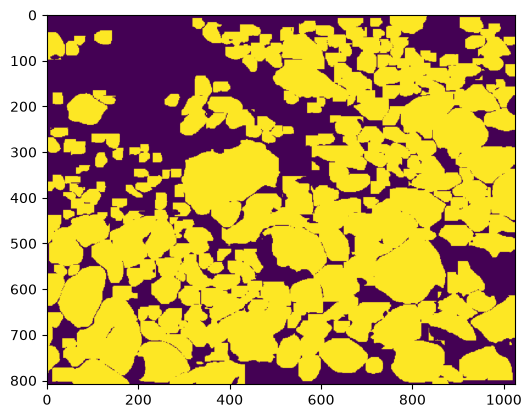

In [83]:
plt.imshow(pred_masks['openpits_10.bmp'])

## 5. Визуализация предсказаний

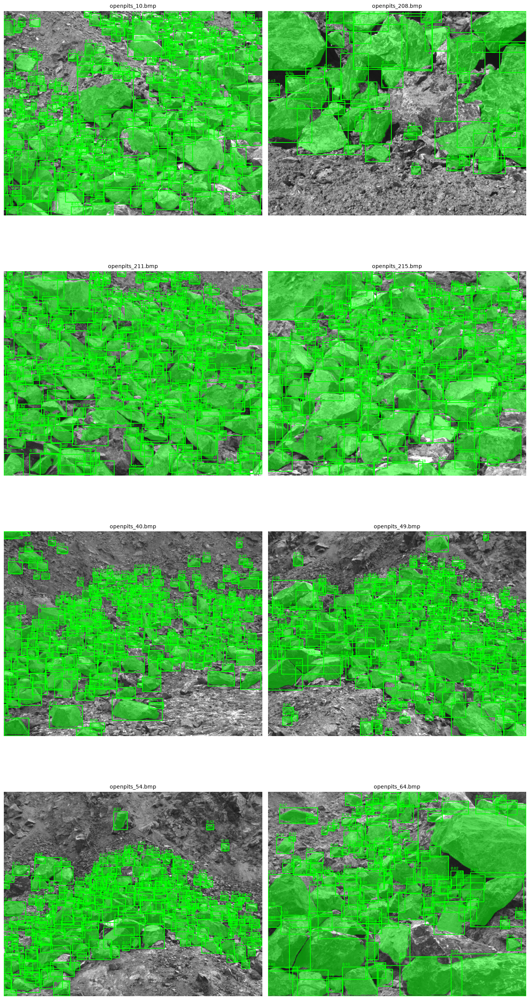

In [84]:
# --- Часть 7: визуализация предсказаний ---

def visualize_predictions(results, n: int = 4):
    """Рисует несколько предсказаний: контуры, bbox, уверенность."""
    show = results[:n]
    cols = 2
    rows = (len(show) + 1) // 2
    fig, axes = plt.subplots(rows, cols, figsize=(14, 7 * rows))
    axes = np.array(axes).reshape(-1)

    for ax, res in zip(axes, show):
        img = res.orig_img.copy()

        # Накладываем полупрозрачную маску
        if res.masks is not None and len(res.masks) > 0:
            overlay = img.copy()
            for mask_tensor in res.masks.data:
                mask = mask_tensor.cpu().numpy()
                mask = cv2.resize(mask, (img.shape[1], img.shape[0]),
                                  interpolation=cv2.INTER_NEAREST)
                color = np.zeros_like(img)
                color[:, :, 1] = 255   # зелёный
                overlay = np.where(mask[:, :, None] > CONF_THRESH,
                                   cv2.addWeighted(img, 0.5, color, 0.5, 0),
                                   overlay)
            img = overlay

        # Bbox + уверенность
        if res.boxes is not None:
            for box in res.boxes:
                x1, y1, x2, y2 = box.xyxy[0].cpu().numpy().astype(int)
                conf = box.conf[0].cpu().numpy()
                cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
                cv2.putText(img, f"{conf:.2f}", (x1, y1 - 5),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)

        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(Path(res.path).name, fontsize=10)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

visualize_predictions(results, n=8)

## 6. Финальный сабмит (RLE, column-major)

In [85]:
import math
def keep_circle(points):
    """Оставляет замкнутый контур (последняя точка = первая, как в COCO)."""
    x = points[-1][0]
    y = points[-1][1]
    x0 = points[0][0]
    y0 = points[0][1]
    if x == x0 and y == y0:
        return points
    return list(points) + [points[0]]
    
def simplify_contour(points, max_points):
    """Прореживает контур до max_points вершин (равномерный сэмплинг)."""
    n = len(points)
    if n <= max_points:
        return points
    step = math.ceil(n / max_points)
    return points[::step]
rows = [["FILE_NAME", "CONFIDENCE", "TARGET"]]
for res in results:
    fname = Path(res.path).name
    if res.masks is None or res.masks.xy is None:
        continue
    w, h = res.orig_shape[1], res.orig_shape[0]
    confs = res.boxes.conf

    for i, mask_xy in enumerate(res.masks.xy):
        conf = float(confs[i])
        poly = simplify_contour(np.asarray(mask_xy, dtype=float), 60)
        poly = keep_circle(poly)

        xy = []
        for px, py in poly:
            nx = min(1.0, max(0.0, px / w))
            ny = min(1.0, max(0.0, py / h))
            xy.append("{:.6f} {:.6f}".format(nx, ny))
        target = "0 " + " ".join(xy)
        rows.append([fname, "{:.4f}".format(conf), target])

out = Path('./submission_cv5.csv')
with open(out, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerows(rows)
print("Сохранено: {} (объектов: {})".format(out, len(rows) - 1))


Сохранено: submission_cv5.csv (объектов: 8325)
